# NEID: the A star WASP-33

This notebook shows how gtellcorr corrects an echelle spectrum with many orders. We use
a NEID spectrum of WASP-33 (WIYN, 2021 October 16), a hot star rotating at 87 km/s.
Unlike the merged PEPSI spectrum of the first two notebooks, NEID delivers more than a
hundred orders, and they are not all fitted. gtellcorr fits the molecular columns jointly
on a set of orders where the telluric bands are, and corrects every order with the
result.

We proceed in four steps:

1. **The exposure.** We read the spectrum and look at two of its orders.
2. **The atmospheric profile.** It comes from ERA5, as before.
3. **The fit.** We see which orders are fitted and which parameters they share, then
   run the fit.
4. **The result.** We look at the fitted columns and at two corrected orders.

**What you need.** gtellcorr with its LBLRTM bundle and reference files, pySME and a
VALD line list for the template (the `stellar_linelist` setting), and the NEID level-2
file `neidL2_20211016T072406.fits` (public, from the NEID archive at NExScI) in
`$GTELLCORR_PAPER_DATA/neid_wasp33/`. The atmospheric profile comes from ERA5, which
needs a Copernicus account (`WEATHER_KEYS`).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt

import gtellcorr as gtc
from gtellcorr.data.atmosphere import full_profile_for_exposure
from gtellcorr.fitting import build_fit_spec
from gtellcorr.plotting import plot_order_fit, plot_profiles

data = Path(os.environ.get("GTELLCORR_PAPER_DATA", "paper_data"))
output = Path(os.environ.get("GTELLCORR_PAPER_OUT", "paper_runs")) / "neid_wasp33"
settings = gtc.Settings.load()
plt.rcParams["figure.dpi"] = 72  # keeps the figures in the notebook small
print("gtellcorr", gtc.__version__)

gtellcorr 0.10.0


## 1. The exposure

WASP-33 is an A5 star; the stellar parameters are those from which the template is
synthesised. We read the directory with the NEID instrument description
(`instrument="WIYN/NEID"`), which says how the level-2 files are laid out and in which
frame their wavelengths are:

In [2]:
star = gtc.Star(name="WASP-33", teff=7430.0, logg=4.3, feh=-0.1, vsini_kms=86.63, vsys_kms=-3.0)
obs = gtc.Observation.from_directory(data / "neid_wasp33", instrument="WIYN/NEID", target=star)
exposure = obs.exposures[0]
instrument = obs.instrument
print(
    f"{exposure.name}\nmid-exposure {exposure.time_utc:%Y-%m-%d %H:%M:%S} UTC, "
    f"airmass {exposure.airmass:.2f}, R = {exposure.resolution:.0f}"
)
print(
    f"{len(instrument.orders)} orders, wavelengths in {instrument.spectral.frame.wavelength_medium}"
)

neidL2_20211016T072406.fits
mid-exposure 2021-10-16 07:26:36 UTC, airmass 1.02, R = 110000
122 orders, wavelengths in vacuum


The spectrum comes with vacuum wavelengths in the observatory frame. gtellcorr
fits in air: `read_order` returns each order with its wavelengths converted
(`wave_fit`), and the results keep the delivered wavelengths as well. Let's look at two
orders: order 76, which holds the O{sub}`2` γ band near 628 nm, and order 89, in a
water band near 730 nm.

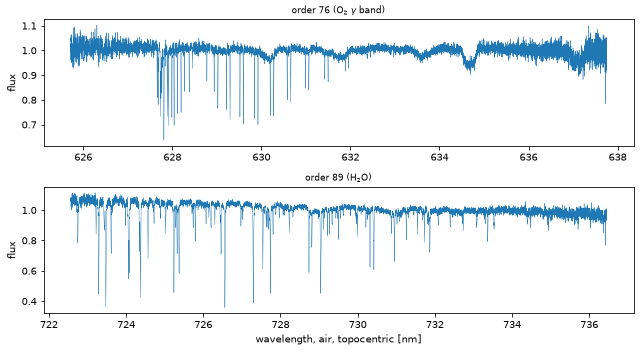

In [3]:
shown = {76: r"O$_2$ $\gamma$ band", 89: r"H$_2$O"}
fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, (number, label) in zip(axes, shown.items(), strict=True):
    order = obs.read_order(exposure, number)
    ax.plot(order.wave_fit, order.flux, lw=0.4)
    ax.set_title(f"order {number} ({label})", fontsize=9)
    ax.set_ylabel("flux")
axes[1].set_xlabel("wavelength, air, topocentric [nm]")
fig.tight_layout()

The stellar lines of WASP-33 are few, and its rotation makes them broad and shallow,
so the narrow telluric lines stand out on a smooth stellar spectrum. This makes the
separation of the two easier than for the K dwarf of the first notebooks.

## 2. The atmospheric profile

The profile above Kitt Peak at the middle of the exposure, built as in the first
notebook (ERA5 below, NRLMSIS-00 above). The NEID header also records the temperature,
pressure and humidity measured at the telescope, which `plot_profiles` marks for
comparison:

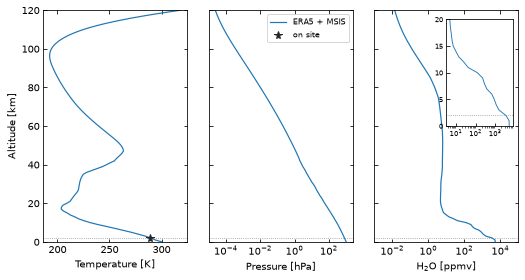

In [4]:
profile = full_profile_for_exposure(exposure, instrument, settings=settings)
fig, axes = plot_profiles(
    {"ERA5 + MSIS": profile},
    site_alt_km=exposure.site.alt_m / 1000,
    onsite=exposure.weather,
)

## 3. The fit

### Which orders are fitted

Most orders hold few telluric lines, and a fit there would constrain the columns
little and the resolving power not at all. gtellcorr therefore fits each molecule on a
set of **anchor orders**, where its bands are strong. The instrument description lists
them for every supported spectrograph (`anchor_orders`); you can give your own with
`molecules.<name>.anchor_orders`, or set it to an empty list to select the orders whose
range overlaps the molecule's bands (`molecules.<name>.bands_nm`).

In [5]:
anchors = instrument.anchor_orders
for molecule, numbers in anchors.items():
    print(f"{molecule}: {len(numbers)} orders {list(numbers)}")
fit_orders = sorted(set(anchors["h2o"]) | set(anchors["o2"]))
print(f"{len(fit_orders)} fit orders of {len(instrument.orders)}")

h2o: 20 orders [78, 79, 84, 85, 86, 87, 88, 89, 90, 96, 97, 98, 99, 100, 104, 105, 106, 107, 108, 109]
o2: 5 orders [83, 84, 85, 92, 93]
23 fit orders of 122


The fit orders are fitted **jointly** (`relcol_mode = "joint_orders"`, the
default). The absorption of a molecule comes from the same column of air in every order,
so the relative columns are shared:

- **shared by all fit orders**: the relative columns $s_{\rm H_2O}$ and $s_{\rm O_2}$
  (each fitted on its own anchor orders; orders 84 and 85 constrain both);
- **one per fit order**: the resolving power $R$, the wavelength correction $v$ and the
  continuum $C$, since the line-spread function, the wavelength solution and the blaze
  change across the detector.

Every order outside the fit is corrected with the shared columns and with the median $R$
and median $v$ of the fit orders. (`relcol_mode = "single_order"` fits every fit order on
its own instead.)

### The settings

For this star we use the template route, written out here with the settings of the
joint fit:

- `stellar = "template"`: the star is modelled with a pySME template, synthesised from
  the parameters above and rotationally broadened with the star's `vsini_kms`. The mask
  route would not do: the atomic line search misses most broad, shallow lines of a
  hot, fast-rotating star (see the route comparison notebook);
- `relcol_mode = "joint_orders"`: the joint fit described above;
- `wavelength.fit = true`, `wavelength.order = 0`, `wavelength.scope = "order"`: one
  wavelength correction per fit order.

`build_fit_spec` shows the free parameters of one fit order, here order 89:

In [6]:
config = gtc.FitConfig.from_dict(
    {
        "stellar": "template",
        "relcol_mode": "joint_orders",
        "wavelength": {"fit": True, "order": 0, "scope": "order"},
    }
)

order = obs.read_order(exposure, 89)
spec = build_fit_spec(
    (float(order.wave_fit.min()), float(order.wave_fit.max())),
    config=config,
    instrument=instrument,
    order=89,
    resolution=exposure.resolution,
)
print(f"order 89: fitted molecules {list(spec.molecules)}")
lo, hi = spec.resolution_bounds
print(
    f"R: start {spec.resolution_init:.0f}, bounds {lo:.0f} to {hi:.0f} "
    f"({hi / spec.resolution_init - 1:.0%} either way)"
)
lo, hi = spec.wave_shift_bounds
print(f"wavelength correction v: bounds {lo:g} to {hi:g} km/s")
print(f"continuum: polynomial of degree {spec.continuum_order}")

order 89: fitted molecules ['h2o']
R: start 110000, bounds 93500 to 126500 (15% either way)
wavelength correction v: bounds -1 to 1 km/s
continuum: polynomial of degree 5


The bounds of $R$ are wider than for PEPSI: the NEID description sets
`resolution.fit_tol = 0.15`, because with the default 8 % many NEID orders ended at a
bound. The radial velocity of the star is measured as before, by cross-correlation with
the template; the velocity grid of the cross-correlation is widened by twice the
`vsini_kms` of the star, so that the broad cross-correlation function fits on it.

Let's run the fit:

In [7]:
result = gtc.run(obs, config, output_dir=output, settings=settings, plot=False)
table = result.exposures[0].order_table
fitted = table[table["used_in_fit"]].copy()
print(table["status"].value_counts().to_string())

status
corrected_not_fitted    92
joint_ok                23
no_valid_wavelength      7


The status column says what happened to each order: `joint_ok` for the 23 fit
orders, `corrected_not_fitted` for the orders corrected with the joint result, and
`no_valid_wavelength` for the few orders without usable data.

## 4. The result

### Fitted parameters

The relative columns, shared by the fit orders:

In [8]:
relcol, relcol_err = {}, {}
for _, row in fitted.iterrows():  # each order lists the molecules fitted in it
    relcol |= json.loads(row["relcol"])
    relcol_err |= json.loads(row["relcol_err"])
for name in relcol:
    print(f"s_{name.upper()}: {relcol[name]:.4f} +- {relcol_err[name]:.4f}")
print(f"joint reduced chi2: {fitted['chi2_reduced_joint'].iloc[0]:.2f}")

s_H2O: 0.9108 +- 0.0006
s_O2: 1.0091 +- 0.0006
joint reduced chi2: 1.46


The spectrum holds 9 % less water than the ERA5 profile, and 0.9 % more O{sub}`2`. The
joint reduced $\chi^2$ of 1.46 shows that one pair of columns describes the 23 orders
close to the noise. The uncertainties are the formal errors of the fit; they do not
include systematic errors, such as those of the line data or of the template.

### The corrected orders

`plot_order_fit` draws an order of the result, whether it was fitted or only corrected.
The two orders we looked at in Section 1 are one of each kind: order 76 holds the
O{sub}`2` γ band but is not an anchor order, so it is only corrected, and order 89 is a
water anchor order:

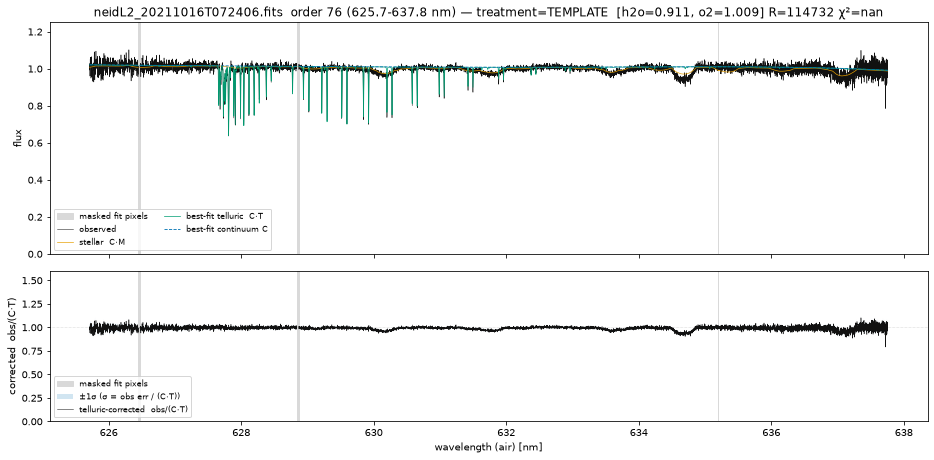

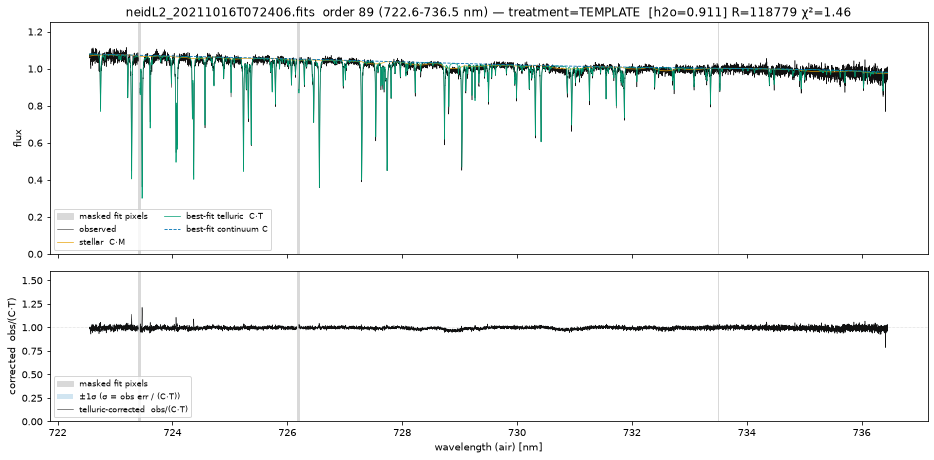

In [9]:
path = result.exposures[0].path
for number in shown:
    fig, axes = plot_order_fit(str(path), order=number, out=False)

In order 76 the O{sub}`2` γ lines are removed, although the order was not fitted: the
shared columns, with the median $R$ and $v$ of the fit orders, describe it well. The
broad, shallow features near 630 and 635 nm belong to the star; the template (orange)
follows them, and they stay in the corrected spectrum. In order 89 the water lines are
removed down to the noise, except in the cores of the deepest lines, where dividing by a
small transmission amplifies both the noise and any error of the model.